# Evaluasi Akhir: Model Terpilih pada Data Testing

Pertemuan 7 memilih model akhir dengan validasi silang pada data training dan menyimpan dua berkas ke Google Drive:

| Berkas | Isi |
| --- | --- |
| `final_config.json` | Versi teks dan pola penyeragamannya, hyperparameter setiap model dasar, model terpilih, dan nilai b |
| `oof_log_proba.npz` | Prediksi *out-of-fold* setiap model, label data training, dan nomor fold setiap baris |

Notebook ini **membaca kedua berkas tersebut** dan tidak menghitung ulang validasi silang. Dengan cara ini, konfigurasi, prediksi *out-of-fold*, dan nilai b pada notebook ini sama persis dengan hasil Pertemuan 7. Karena itu, notebook ini dijalankan **setelah** notebook Pertemuan 7 selesai.

Notebook ini menjalankan lima langkah:

1. **Membaca hasil Pertemuan 7** dan menampilkan ringkasan validasi silangnya.
2. **Melatih *meta-model*** pada prediksi *out-of-fold* model dasar, dengan nilai b dari Pertemuan 7.
3. **Melatih model dasar akhir** pada seluruh data training.
4. **Menguji model akhir satu kali pada data testing**, lalu membandingkannya dengan baseline Pertemuan 3 pada data testing yang sama.
5. **Menginterpretasikan** model akhir.

Data testing hanya dipakai pada bagian E. Seluruh konfigurasi dan nilai b sudah ditetapkan pada Pertemuan 7, sebelum data testing dipakai, dan tidak diubah setelah hasilnya terlihat.

# A. Persiapan

## A.1 Penyimpanan Hasil dan Hasil Pertemuan 7

Notebook ini membutuhkan sekitar 1 jam. Prediksi data testing setiap model disimpan ke Google Drive segera setelah dihitung. Jika runtime terputus, jalankan ulang semua sel; prediksi yang sudah tersimpan akan dimuat, bukan dihitung ulang.

Sel berikut menghubungkan Google Drive, langsung menulis satu berkas uji ke folder hasil, lalu membaca `final_config.json` dan `oof_log_proba.npz` dari folder hasil Pertemuan 7. Jika Google Drive gagal terhubung atau hasil Pertemuan 7 belum ada, notebook berhenti di sel ini.

In [1]:
import sys
import subprocess
import os
import re
import time
import gc
import json
import warnings

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')  # tanpa try/except: kegagalan menghentikan notebook di sini
    DRIVE_ROOT = '/content/drive/MyDrive/Group1_ML'
else:
    DRIVE_ROOT = '.'  # hanya untuk menjalankan notebook di luar Colab
M07_DIR = f'{DRIVE_ROOT}/m07_artifacts'
ARTIFACT_DIR = f'{DRIVE_ROOT}/final_evaluation'
os.makedirs(f'{ARTIFACT_DIR}/test', exist_ok=True)
with open(os.path.join(ARTIFACT_DIR, '_write_test.txt'), 'w') as handle:
    handle.write('ok')  # menulis ke folder hasil sekarang, sebelum pekerjaan panjang dimulai

with open(f'{M07_DIR}/final_config.json') as handle:
    config = json.load(handle)
m07_oof = dict(np.load(f'{M07_DIR}/oof_log_proba.npz'))
y_cv, fold_of_row = m07_oof.pop('y_train'), m07_oof.pop('fold_of_row')

FINAL_NAME = config['final_model']
BASE_NAMES = config['final_model_bases']  # nama model dasar pada Pertemuan 7, misalnya 'LR V3'
BASE_MODELS = [name.split()[0] for name in BASE_NAMES]  # 'MNB', 'LR', 'LightGBM'
HAM_BIAS = config['ham_bias_b']
HAM_RECALL_TARGET = config['ham_recall_target']
RANDOM_STATE = config['random_state']

print('Hasil disimpan di      :', os.path.abspath(ARTIFACT_DIR))
print('Hasil Pertemuan 7 dari :', os.path.abspath(M07_DIR))
print('Prediksi tersimpan     :', sorted(os.listdir(f'{ARTIFACT_DIR}/test')))
display(pd.DataFrame({'konfigurasi': {
    'Model akhir': f"{FINAL_NAME} (model dasar: {', '.join(BASE_NAMES)})",
    'Teks': config['text_variant'],
    'Multinomial Naive Bayes': f"{config['mnb']['representation']}, alpha={config['mnb']['alpha']}"
                               + (f", chi-square k={config['mnb']['chi2_k']:,}" if config['mnb']['chi2_k'] else ''),
    'Logistic Regression': f"{config['lr']['representation']}, C={config['lr']['C']}",
    'LightGBM': f"{config['lightgbm']['representation']}, {config['lightgbm']['n_estimators']} pohon, "
                f"learning_rate={config['lightgbm']['learning_rate']}, num_leaves={config['lightgbm']['num_leaves']}, "
                f"colsample_bytree={config['lightgbm']['colsample_bytree']}",
    'Meta-model': config['stacking_meta'],
    'Threshold Ham': f"b = {HAM_BIAS:.3f} (Ham Recall minimal {HAM_RECALL_TARGET:.1%} pada validasi silang)",
}}))

Mounted at /content/drive
Hasil disimpan di      : /content/drive/MyDrive/Group1_ML/final_evaluation
Hasil Pertemuan 7 dari : /content/drive/MyDrive/Group1_ML/m07_artifacts
Prediksi tersimpan     : []


,konfigurasi
Model akhir,Stacking MNB + LR + LightGBM (model dasar: MNB...
Teks,V3
Multinomial Naive Bayes,"count unigram+bigram, min_df=2, alpha=2.0"
Logistic Regression,"tfidf unigram, sublinear_tf, C=64"
LightGBM,"unigram count, min_df=20, 125 pohon, learning_..."
Meta-model,StandardScaler + LogisticRegression on log-pro...
Threshold Ham,b = 1.777 (Ham Recall minimal 99.5% pada valid...


## A.2 Data

Dataset, preprocessing, dan pembagian data sama dengan Pertemuan 3 sampai 7. Kali ini data testing **disimpan** karena dipakai pada bagian E.

In [2]:
def ensure(package, module=None):
    try:
        __import__(module or package)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

ensure('datasets')
ensure('lightgbm')

import matplotlib.pyplot as plt
import sklearn
import lightgbm as lgb
from datasets import load_dataset
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore', message='X does not have valid feature names')
pd.set_option('display.max_colwidth', 200)

DATASET_NAME = 'locuoco/the-biggest-spam-ham-phish-email-dataset-300000'
LABEL_NAMES = {0: 'Ham', 1: 'Phish', 2: 'Spam'}
CLASS_IDS = [0, 1, 2]
CLASS_ORDER = [LABEL_NAMES[c] for c in CLASS_IDS]

raw_df = load_dataset(DATASET_NAME, split='train').to_pandas()
data = raw_df[['text', 'label']].dropna(subset=['text', 'label']).copy()
data = data[data['label'].isin(CLASS_IDS)].copy()
data['label'] = data['label'].astype(int)
data['clean_text'] = data['text'].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()
data = data[data['clean_text'].ne('')].copy()
data['dedup_key'] = data['clean_text'].str.lower()
labels_per_key = data.groupby('dedup_key')['label'].nunique()
data = data.loc[~data['dedup_key'].isin(labels_per_key[labels_per_key.gt(1)].index)]
df_clean = (
    data.drop_duplicates(subset=['dedup_key'], keep='first')
    [['clean_text', 'label']]
    .rename(columns={'clean_text': 'text'})
    .reset_index(drop=True)
)
del raw_df, data
gc.collect()

X_train, X_test, y_train, y_test = train_test_split(
    df_clean['text'], df_clean['label'],
    test_size=0.20, random_state=RANDOM_STATE, stratify=df_clean['label']
)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.to_numpy(), y_test.to_numpy()
del df_clean
gc.collect()

print(f'Data training: {len(X_train):,} | Data testing: {len(X_test):,}')
print(f'Versi library: scikit-learn {sklearn.__version__}, lightgbm {lgb.__version__}, pandas {pd.__version__}, numpy {np.__version__}')

README.md:   0%|          | 0.00/990 [00:00<?, ?B/s]

df.csv: reconstructing file:   0%|          |  0.00B /  631MB            

df.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/365448 [00:00<?, ? examples/s]

Data training: 223,152 | Data testing: 55,789
Versi library: scikit-learn 1.6.1, lightgbm 4.6.0, pandas 2.2.3, numpy 2.4.6


## A.3 Teks V3

Setiap kelas berasal dari sumber yang memproses teks secara berbeda:

| Ciri format | Sumber Ham dan Spam | Sumber Phish |
| --- | --- | --- |
| Angka | diganti `escapenumber` | angka asli |
| *Timestamp header* | ada, angkanya diganti `escapenumber` | ada, angka asli |
| *Stopword* (`the`, `to`, `and`, …) | ada | sudah dihapus |
| Tanda baca | dipisahkan dengan spasi (`http www site com`) | dihapus tanpa spasi (`httpwwwsitecom`) |

Jika ciri ini dibiarkan, model dapat mengenali Phish dari formatnya, misalnya dari tidak adanya kata `the`. Email nyata tidak memiliki perbedaan seperti ini. Teks V3 menyeragamkan semua ciri tersebut dengan tujuh langkah yang sama untuk setiap kelas:

| Langkah | Perubahan | Alasan |
| ---: | --- | --- |
| 1 | Tanda baca diganti spasi | Pola pada langkah berikutnya dapat dikenali dengan cara yang sama pada semua kelas. Kata yang dipakai vectorizer tidak berubah. |
| 2 | *Timestamp header* dihapus, termasuk yang angkanya sudah menjadi `escapenumber` | *Timestamp* adalah bagian *header*, bukan isi pesan. |
| 3 | Kata yang diawali `http` (terpisah atau menyatu) diganti `urltoken` | Tautan menyatu hanya ada pada Phish; setelah langkah ini setiap tautan menjadi satu token yang sama. |
| 4 | Token `www`, `com`, `net`, `org`, `edu`, `gov` yang berdiri sendiri dihapus | Token ini hanya muncul terpisah pada Ham dan Spam karena cara sumbernya memisahkan tanda baca. |
| 5 | Kata yang mengandung angka dan token `escape…` diganti `numtoken` | Format angka berbeda antar sumber (Hipotesis 4). |
| 6 | Nama bulan dan hari yang tersisa diganti `datetoken` | Penulisan tanggal di dalam isi pesan menjadi seragam. |
| 7 | *Stopword* bahasa Inggris dari daftar NLTK (179 kata) dihapus | Sumber Phish sudah tidak memuat satu pun kata dari daftar NLTK, sedangkan kata dari daftar lain yang lebih panjang (misalnya `please`, `call`, `system`) masih ada. Jadi daftar NLTK adalah daftar yang dipakai sumber Phish. Menghapus daftar yang sama dari semua kelas menyeragamkan format tanpa membuang kata isi seperti `please`. |

Urutan langkah penting: langkah 2 dan 3 membutuhkan angka asli, sehingga harus berjalan sebelum langkah 5.

Pola setiap langkah dibaca dari `final_config.json` Pertemuan 7, sehingga penyeragaman teks sama persis dengan yang dipakai saat model dipilih. Sel berikut membentuk teks V3 pada data training dan data testing. Tabel di bawahnya membandingkan ciri format setiap kelas sebelum dan sesudah penyeragaman.

In [3]:
PUNCTUATION_PATTERN = config['punctuation_pattern']
TIMESTAMP_PATTERN = config['timestamp_pattern']
LINK_PATTERN = config['link_pattern']
WEB_PARTS_PATTERN = config['web_parts_pattern']
NUMBER_PATTERN = config['number_pattern']
DATE_PATTERN = config['date_pattern']
NLTK_STOPWORDS = set(config['stopwords'])  # daftar stopword bahasa Inggris NLTK (179 kata)
STOPWORD_PATTERN = r'\b(?:' + '|'.join(sorted(NLTK_STOPWORDS, key=len, reverse=True)) + r')\b'


def normalize_v3(texts):
    return (texts.str.lower()
            .str.replace(PUNCTUATION_PATTERN, ' ', regex=True)
            .str.replace(TIMESTAMP_PATTERN, ' ', regex=True)
            .str.replace(LINK_PATTERN, ' urltoken ', regex=True)
            .str.replace(WEB_PARTS_PATTERN, ' ', regex=True)
            .str.replace(NUMBER_PATTERN, ' numtoken ', regex=True)
            .str.replace(DATE_PATTERN, ' datetoken ', regex=True)
            .str.replace(STOPWORD_PATTERN, ' ', regex=True))


start = time.perf_counter()
V3_train, V3_test = normalize_v3(X_train), normalize_v3(X_test)
print(f'Teks V3 selesai dalam {time.perf_counter() - start:.0f} detik')

stopwords = NLTK_STOPWORDS


def stopword_share(text):
    words = text.split()
    return np.nan if len(words) < 5 else sum(word in stopwords for word in words) / len(words)


raw_lower = X_train.str.lower()
format_rows = []
for c in CLASS_IDS:
    mask = y_train == c
    format_rows.append({
        'kelas': LABEL_NAMES[c],
        'memuat "the", asli (%)': raw_lower[mask].str.contains(r'\bthe\b').mean() * 100,
        'memuat "the", V3 (%)': V3_train[mask].str.contains(r'\bthe\b').mean() * 100,
        'median porsi stopword, asli (%)': raw_lower[mask].map(stopword_share).median() * 100,
        'median porsi stopword, V3 (%)': V3_train[mask].map(stopword_share).median() * 100,
        'tautan menyatu, asli (%)': raw_lower[mask].str.contains(r'\bhttp[a-z0-9]{3,}').mean() * 100,
        'memuat tanda baca, asli (%)': raw_lower[mask].str.contains(r'[^\w\s]').mean() * 100,
    })
del raw_lower
display(pd.DataFrame(format_rows).round(1))
display(pd.DataFrame({'teks asli': [X_train.iloc[0][:150]], 'teks V3': [' '.join(V3_train.iloc[0].split())[:150]]}))

Teks V3 selesai dalam 282 detik


,kelas,"memuat ""the"", asli (%)","memuat ""the"", V3 (%)","median porsi stopword, asli (%)","median porsi stopword, V3 (%)","tautan menyatu, asli (%)","memuat tanda baca, asli (%)"
0,Ham,65.6,0.0,28.2,0.0,0.0,54.4
1,Phish,0.0,0.0,0.0,0.0,39.1,0.0
2,Spam,51.8,0.0,24.5,0.0,0.0,49.2


,teks asli,teks V3
0,really wish would feel way make apology consider expressed friday night anything honesty true emotion would like feel comfortable expressing feelings,really wish would feel way make apology consider expressed datetoken night anything honesty true emotion would like feel comfortable expressing feelin


# B. Hasil Validasi Silang Pertemuan 7

## B.1 Model Dasar dan Model Akhir

Tabel berikut dihitung dari prediksi *out-of-fold* Pertemuan 7 dengan lima fold yang sama. Model dasar memakai threshold bawaan, sedangkan model akhir ditampilkan dengan threshold bawaan dan dengan nilai b.

In [4]:
from sklearn.metrics import accuracy_score, average_precision_score, confusion_matrix, f1_score

ERROR_PAIRS = [(0, 2), (0, 1), (1, 0), (1, 2), (2, 1), (2, 0)]
ERROR_LABELS = [f'{LABEL_NAMES[a]} → {LABEL_NAMES[p]}' for a, p in ERROR_PAIRS]


def compute_metrics(y_true, log_proba, ham_bias=0.0):
    adjusted = log_proba.copy()
    adjusted[:, 0] += ham_bias
    y_pred = adjusted.argmax(axis=1)
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    metrics = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro F1': f1_score(y_true, y_pred, average='macro'),
        'Ham Recall': cm[0, 0] / cm[0].sum(),
        'Phish Recall': cm[1, 1] / cm[1].sum(),
        'Phish Precision': cm[1, 1] / max(cm[:, 1].sum(), 1),
        'PR-AUC Phish': average_precision_score(y_true == 1, log_proba[:, 1]),
    }
    metrics.update({label: int(cm[a, p]) for label, (a, p) in zip(ERROR_LABELS, ERROR_PAIRS)})
    return metrics, y_pred


def fold_mean(log_proba, ham_bias=0.0):
    return pd.DataFrame([compute_metrics(y_cv[fold_of_row == k], log_proba[fold_of_row == k], ham_bias)[0]
                         for k in np.unique(fold_of_row)])


def oof_of(name):
    return m07_oof[name.replace(' ', '_')]


stack_oof = oof_of(FINAL_NAME)
cv_rows = []
for label, log_proba, bias in ([(name, oof_of(name), 0.0) for name in BASE_NAMES]
                               + [(f'{FINAL_NAME}, threshold bawaan', stack_oof, 0.0),
                                  (f'{FINAL_NAME}, b = {HAM_BIAS:.3f}', stack_oof, HAM_BIAS)]):
    scores = fold_mean(log_proba, bias)
    cv_rows.append({'model': label, **{m: scores[m].mean() for m in ['Macro F1', 'Ham Recall', 'Phish Recall', 'Phish Precision']},
                    'Macro F1 simpangan baku': scores['Macro F1'].std(ddof=0)})
display(pd.DataFrame(cv_rows).round(4))
cv_scores = fold_mean(stack_oof, HAM_BIAS)

,model,Macro F1,Ham Recall,Phish Recall,Phish Precision,Macro F1 simpangan baku
0,MNB V3 (alpha=2.0),0.8356,0.9893,0.6165,0.7560,0.0012
1,LR V3,0.8658,0.9864,0.6776,0.7732,0.0028
2,LightGBM V3,0.8867,0.9764,0.6757,0.9000,0.0012
3,"Stacking MNB + LR + LightGBM, threshold bawaan",0.8909,0.9879,0.6821,0.8901,0.0013
4,"Stacking MNB + LR + LightGBM, b = 1.777",0.8855,0.9950,0.6783,0.8925,0.0011


## B.2 Ringkasan Hipotesis 4 dan 5

Pertemuan 7 menguji apakah model mengenali kelas dari format sumber datanya. Tabel berikut menampilkan Macro F1 validasi silang pada setiap versi teks:

| Versi | Perubahan |
| --- | --- |
| V0 | Teks asli |
| V1 | Tanda baca diganti spasi, angka diganti `numtoken` |
| V2 | V1 ditambah penghapusan *timestamp header* dan penyeragaman nama bulan dan hari (Hipotesis 4) |
| V3 | V2 ditambah penyeragaman tautan dan penghapusan *stopword* (Hipotesis 5) |

In [5]:
version_rows = []
for model, prefix in [('Multinomial Naive Bayes', 'MNB unigram'), ('Logistic Regression', 'LR')]:
    row = {'model': model}
    for version in ['V0', 'V1', 'V2', 'V3']:
        row[version] = fold_mean(oof_of(f'{prefix} {version}'))['Macro F1'].mean()
    version_rows.append(row)
version_table = pd.DataFrame(version_rows).set_index('model')
version_table['H4: V2 − V0'] = version_table['V2'] - version_table['V0']
version_table['H5: V3 − V2'] = version_table['V3'] - version_table['V2']
display(version_table.round(4))
h4_drop, h5_drop = version_table['H4: V2 − V0'], version_table['H5: V3 − V2']
display(Markdown(
    f"Menyeragamkan angka dan tanggal menurunkan Macro F1 sebesar {-h4_drop.max():.4f} sampai {-h4_drop.min():.4f}, "
    f"dan menyeragamkan *stopword* serta tautan menurunkan Macro F1 sebesar {-h5_drop.max():.4f} sampai {-h5_drop.min():.4f}. "
    "Sebagian performa pada teks asli berasal dari format sumber data, sehingga model akhir memakai teks V3."
))

,V0,V1,V2,V3,H4: V2 − V0,H5: V3 − V2
model,,,,,,
Multinomial Naive Bayes,0.9344,0.8956,0.8900,0.8016,-0.0444,-0.0884
Logistic Regression,0.9687,0.9476,0.9423,0.8658,-0.0263,-0.0766


Menyeragamkan angka dan tanggal menurunkan Macro F1 sebesar 0.0263 sampai 0.0444, dan menyeragamkan *stopword* serta tautan menurunkan Macro F1 sebesar 0.0766 sampai 0.0884. Sebagian performa pada teks asli berasal dari format sumber data, sehingga model akhir memakai teks V3.

# C. Meta-Model

*Meta-model* dibentuk dengan cara yang sama seperti Pertemuan 7: log-probabilitas *out-of-fold* setiap model dasar dibatasi pada rentang −30 sampai 0, distandarkan, lalu menjadi fitur Logistic Regression. *Meta-model* akhir dilatih pada seluruh prediksi *out-of-fold* data training dari Pertemuan 7.

Nilai b tidak dihitung ulang: nilai b dari Pertemuan 7 dipilih pada prediksi *out-of-fold* *meta-model* yang sama, sebelum data testing dipakai.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def meta_features(log_probas):
    return np.hstack([np.clip(log_probas[model], -30, 0) for model in BASE_MODELS])


meta_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
meta_model.fit(meta_features({model: oof_of(name) for model, name in zip(BASE_MODELS, BASE_NAMES)}), y_cv)
print(f'Meta-model dilatih pada {len(y_cv):,} prediksi out-of-fold dari {len(BASE_MODELS)} model dasar: {BASE_MODELS}')
print(f'Nilai b = {HAM_BIAS:.3f} (dari Pertemuan 7)')

Meta-model dilatih pada 223,152 prediksi out-of-fold dari 3 model dasar: ['MNB', 'LR', 'LightGBM']
Nilai b = 1.777 (dari Pertemuan 7)


# D. Model Akhir pada Seluruh Data Training

Sel berikut melatih setiap model dasar pada seluruh 223.152 pesan training V3 dengan konfigurasi dari Pertemuan 7, lalu menghitung log-probabilitas data testing. Prediksi setiap model disimpan segera setelah selesai. Logistic Regression selalu dilatih, karena modelnya juga dipakai untuk interpretasi pada bagian F.

Baseline Pertemuan 3 juga dilatih dengan konfigurasi yang sama: teks asli, TF-IDF unigram dengan seluruh kosakata (`sublinear_tf=True`), dan Multinomial Naive Bayes `alpha=1.0`.

Langkah ini membutuhkan sekitar 45 menit.

In [7]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

LGBM_PARAMS = {key: value for key, value in config['lightgbm'].items() if key != 'representation'}
LGBM_MIN_DF = int(re.search(r'min_df=(\d+)', config['lightgbm']['representation']).group(1))
counts = {}


def count_features():
    # Count unigram + bigram dibentuk sekali dan dipakai bersama oleh Multinomial Naive Bayes dan LightGBM.
    if not counts:
        vectorizer = CountVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, dtype=np.float32)
        counts['fit'] = vectorizer.fit_transform(V3_train)
        counts['test'] = vectorizer.transform(V3_test)
        counts['unigram'] = np.array([' ' not in term for term in vectorizer.get_feature_names_out()])
    return counts['fit'], counts['test'], counts['unigram']


def fit_predict_final(model):
    if model == 'LR':
        vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 1), sublinear_tf=True, dtype=np.float32)
        fitted = LogisticRegression(C=config['lr']['C'], max_iter=1000, random_state=RANDOM_STATE)
        fitted.fit(vectorizer.fit_transform(V3_train), y_train)
        return fitted.predict_log_proba(vectorizer.transform(V3_test)), (vectorizer, fitted)
    X_fit, X_test_counts, unigram = count_features()
    if model == 'MNB':
        steps = [('classifier', MultinomialNB(alpha=config['mnb']['alpha']))]
        if config['mnb']['chi2_k']:
            steps.insert(0, ('chi2', SelectKBest(chi2, k=config['mnb']['chi2_k'])))
        fitted = Pipeline(steps).fit(X_fit, y_train)
        return fitted.predict_log_proba(X_test_counts), fitted
    document_frequency = np.asarray((X_fit > 0).sum(axis=0)).ravel()
    columns = np.flatnonzero(unigram & (document_frequency >= LGBM_MIN_DF))
    fitted = lgb.LGBMClassifier(**LGBM_PARAMS, verbose=-1, n_jobs=-1).fit(X_fit[:, columns], y_train)
    return np.log(np.clip(fitted.predict_proba(X_test_counts[:, columns]), 1e-15, 1.0)), (fitted, columns)


test_log_proba, final_models = {}, {}
for model in dict.fromkeys(BASE_MODELS + ['LR']):
    path = f'{ARTIFACT_DIR}/test/{model}_test.npy'
    if os.path.exists(path) and model != 'LR':
        test_log_proba[model] = np.load(path)
        continue
    start = time.perf_counter()
    test_log_proba[model], final_models[model] = fit_predict_final(model)
    np.save(path, test_log_proba[model])
    print(f'{model} akhir: {(time.perf_counter() - start) / 60:.1f} menit, tersimpan')
    _ = gc.collect()
counts.clear()

baseline_path = f'{ARTIFACT_DIR}/test/baseline_test.npy'
if os.path.exists(baseline_path):
    baseline_log_proba = np.load(baseline_path)
else:
    baseline = Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 1), sublinear_tf=True)),
        ('classifier', MultinomialNB(alpha=1.0)),
    ]).fit(X_train, y_train)
    baseline_log_proba = baseline.predict_log_proba(X_test)
    np.save(baseline_path, baseline_log_proba)
print('Prediksi data testing lengkap.')

MNB akhir: 3.4 menit, tersimpan
LR akhir: 3.3 menit, tersimpan
LightGBM akhir: 33.0 menit, tersimpan
Prediksi data testing lengkap.


# E. Evaluasi pada Data Testing

## E.1 Hasil Utama

Sel ini adalah satu-satunya bagian yang memakai label data testing. Tabel berikut membandingkan:

| Baris | Model | Threshold |
| --- | --- | --- |
| Baseline Pertemuan 3 | TF-IDF + Multinomial Naive Bayes pada teks asli | Bawaan |
| Model akhir, threshold bawaan | Model terpilih Pertemuan 7 pada teks V3 | b = 0 |
| **Model akhir** | Model terpilih Pertemuan 7 pada teks V3 | b dari Pertemuan 7 |

In [8]:
F_test = meta_features(test_log_proba)
final_test_log_proba = meta_model.predict_log_proba(F_test)

results = {}
results['Baseline Pertemuan 3'], baseline_pred = compute_metrics(y_test, baseline_log_proba)
results['Model akhir, threshold bawaan'], _ = compute_metrics(y_test, final_test_log_proba)
results['Model akhir'], final_pred = compute_metrics(y_test, final_test_log_proba, HAM_BIAS)
test_table = pd.DataFrame(results).T
display(test_table.round(4))

final = results['Model akhir']
base = results['Baseline Pertemuan 3']
ham_total = int((y_test == 0).sum())
display(Markdown(
    f"Pada data testing, model akhir memperoleh Macro F1 **{final['Macro F1']:.4f}** dan Ham Recall **{final['Ham Recall']:.4f}** "
    f"(target 0,995 {'tercapai' if final['Ham Recall'] >= HAM_RECALL_TARGET else 'tidak tercapai'}). "
    f"Model ini kehilangan {final['Ham → Spam'] + final['Ham → Phish']:,} dari {ham_total:,} email sah, "
    f"serta meloloskan {final['Phish → Ham']:,} phishing dan {final['Spam → Ham']:,} spam ke kotak masuk. "
    f"Dibandingkan baseline Pertemuan 3, Macro F1 naik {final['Macro F1'] - base['Macro F1']:.4f} "
    f"dan Phish Recall naik {final['Phish Recall'] - base['Phish Recall']:.4f}."
))

,Accuracy,Macro F1,Ham Recall,Phish Recall,Phish Precision,PR-AUC Phish,Ham → Spam,Ham → Phish,Phish → Ham,Phish → Spam,Spam → Phish,Spam → Ham
Baseline Pertemuan 3,0.8881,0.8377,0.9932,0.5316,0.9844,0.8863,167.0,7.0,538.0,3475.0,65.0,1991.0
"Model akhir, threshold bawaan",0.9319,0.8967,0.9882,0.6932,0.9029,0.8887,289.0,13.0,33.0,2596.0,626.0,244.0
Model akhir,0.9258,0.8913,0.9963,0.6901,0.9055,0.8887,89.0,5.0,107.0,2548.0,612.0,781.0


Pada data testing, model akhir memperoleh Macro F1 **0.8913** dan Ham Recall **0.9963** (target 0,995 tercapai). Model ini kehilangan 94 dari 25,548 email sah, serta meloloskan 107 phishing dan 781 spam ke kotak masuk. Dibandingkan baseline Pertemuan 3, Macro F1 naik 0.0536 dan Phish Recall naik 0.1585.

## E.2 Validasi Silang vs Data Testing

Jika hasil data testing jauh di bawah hasil validasi silang, model atau threshold terlalu menyesuaikan diri dengan data training. Tabel berikut membandingkan keduanya pada threshold yang sama (b dari Pertemuan 7).

In [9]:
comparison = pd.DataFrame({
    'validasi silang (training)': [cv_scores[m].mean() for m in ['Macro F1', 'Ham Recall', 'Phish Recall', 'Phish Precision']],
    'data testing': [final[m] for m in ['Macro F1', 'Ham Recall', 'Phish Recall', 'Phish Precision']],
}, index=['Macro F1', 'Ham Recall', 'Phish Recall', 'Phish Precision'])
comparison['selisih'] = comparison['data testing'] - comparison['validasi silang (training)']
display(comparison.round(4))
gap = comparison.loc['Macro F1', 'selisih']
display(Markdown(
    f"Selisih Macro F1 antara data testing dan validasi silang adalah {gap:+.4f}. "
    + ('Hasil validasi silang menggambarkan performa pada data baru dengan baik.' if abs(gap) < 0.01 else
       'Selisih ini cukup besar, sehingga hasil validasi silang perlu dibaca dengan hati-hati.')
))

,validasi silang (training),data testing,selisih
Macro F1,0.8855,0.8913,0.0058
Ham Recall,0.9950,0.9963,0.0013
Phish Recall,0.6783,0.6901,0.0119
Phish Precision,0.8925,0.9055,0.0130


Selisih Macro F1 antara data testing dan validasi silang adalah +0.0058. Hasil validasi silang menggambarkan performa pada data baru dengan baik.

## E.3 Interval Kepercayaan

Satu angka dari data testing bergantung pada pesan yang kebetulan masuk ke data testing. *Bootstrap* mengambil ulang 55.789 prediksi data testing secara acak dengan pengembalian sebanyak 1.000 kali, lalu menghitung metrik pada setiap sampel ulang. Rentang 2,5% sampai 97,5% dari hasilnya adalah interval kepercayaan 95%.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
codes_final = y_test * 3 + final_pred
codes_base = y_test * 3 + baseline_pred


def metrics_from_codes(codes):
    cm = np.bincount(codes, minlength=9).reshape(3, 3).astype(float)
    precision = np.diag(cm) / np.maximum(cm.sum(axis=0), 1)
    recall = np.diag(cm) / np.maximum(cm.sum(axis=1), 1)
    f1 = np.where(precision + recall > 0, 2 * precision * recall / np.maximum(precision + recall, 1e-12), 0)
    return f1.mean(), recall[0], recall[1]


boot = {'Model akhir': [], 'Baseline Pertemuan 3': []}
for _ in range(1000):
    sample = rng.integers(0, len(y_test), size=len(y_test))
    boot['Model akhir'].append(metrics_from_codes(codes_final[sample]))
    boot['Baseline Pertemuan 3'].append(metrics_from_codes(codes_base[sample]))
ci_rows = []
for name, values in boot.items():
    values = np.array(values)
    for column, metric in enumerate(['Macro F1', 'Ham Recall', 'Phish Recall']):
        low, high = np.percentile(values[:, column], [2.5, 97.5])
        ci_rows.append({'model': name, 'metrik': metric, 'nilai': results[name][metric], 'batas bawah 95%': low, 'batas atas 95%': high})
ci_table = pd.DataFrame(ci_rows)
display(ci_table.round(4))
final_low = ci_table.query("model == 'Model akhir' and metrik == 'Macro F1'")['batas bawah 95%'].iloc[0]
base_high = ci_table.query("model == 'Baseline Pertemuan 3' and metrik == 'Macro F1'")['batas atas 95%'].iloc[0]
display(Markdown(
    'Interval Macro F1 model akhir dan baseline tidak bertumpang tindih, sehingga perbedaannya bukan kebetulan pemilihan data testing.'
    if final_low > base_high else
    'Interval Macro F1 model akhir dan baseline bertumpang tindih, sehingga perbedaannya perlu dibaca dengan hati-hati.'
))

,model,metrik,nilai,batas bawah 95%,batas atas 95%
0,Model akhir,Macro F1,0.8913,0.8878,0.8946
1,Model akhir,Ham Recall,0.9963,0.9956,0.9971
2,Model akhir,Phish Recall,0.6901,0.6798,0.6997
3,Baseline Pertemuan 3,Macro F1,0.8377,0.8341,0.8416
4,Baseline Pertemuan 3,Ham Recall,0.9932,0.9921,0.9941
5,Baseline Pertemuan 3,Phish Recall,0.5316,0.5215,0.5428


Interval Macro F1 model akhir dan baseline tidak bertumpang tindih, sehingga perbedaannya bukan kebetulan pemilihan data testing.

## E.4 Confusion Matrix

Confusion matrix berikut dinormalisasi per baris: setiap baris menunjukkan ke kelas mana pesan dari satu kelas aktual diprediksi. Setiap sel menampilkan persentase dan jumlah pesan.

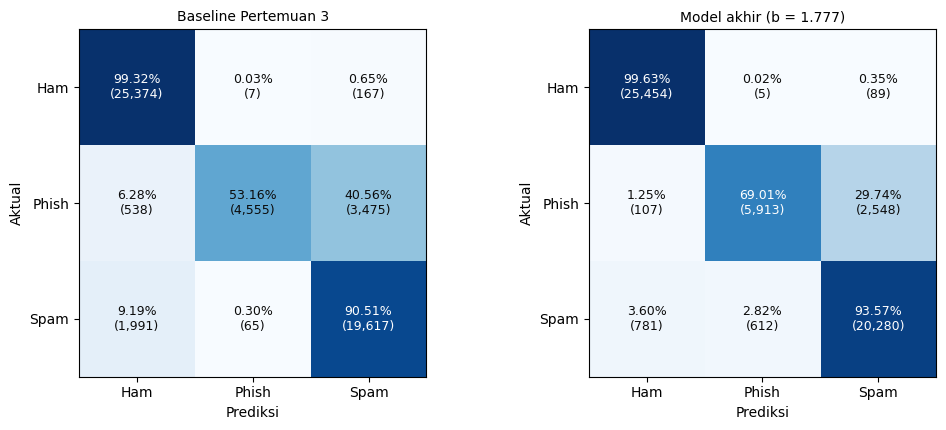

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for ax, (title, y_pred) in zip(axes, [('Baseline Pertemuan 3', baseline_pred), (f'Model akhir (b = {HAM_BIAS:.3f})', final_pred)]):
    counts = confusion_matrix(y_test, y_pred, labels=CLASS_IDS)
    share = counts / counts.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f'{share[i, j] * 100:.2f}%\n({counts[i, j]:,})', ha='center', va='center',
                    fontsize=9, color='white' if share[i, j] > 0.6 else '#0b0b0b')
    ax.set_xticks(range(3), CLASS_ORDER)
    ax.set_yticks(range(3), CLASS_ORDER)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

# F. Interpretasi Model Akhir

## F.1 Kepercayaan Meta-Model pada Setiap Model Dasar

*Meta-model* memberi bobot pada setiap fitur masukan, yaitu log-probabilitas setiap kelas dari setiap model dasar. Karena fitur distandarkan, besar bobot dapat dibandingkan langsung. Bobot positif berarti fitur tersebut menaikkan peluang kelas pada baris tabel.

In [12]:
meta_lr = meta_model.named_steps['logisticregression']
feature_names = [f'{model}: log P({LABEL_NAMES[c]})' for model in BASE_MODELS for c in CLASS_IDS]
meta_weights = pd.DataFrame(meta_lr.coef_, index=[LABEL_NAMES[c] for c in meta_lr.classes_], columns=feature_names)
display(meta_weights.round(3))

model_share = pd.DataFrame({
    model: meta_weights[[f'{model}: log P({LABEL_NAMES[c]})' for c in CLASS_IDS]].abs().sum(axis=1)
    for model in BASE_MODELS
})
model_share = model_share.div(model_share.sum(axis=1), axis=0) * 100
display(Markdown('**Porsi bobot absolut setiap model dasar per kelas (%)**'))
display(model_share.round(1))
display(Markdown('\n'.join(
    f"- Untuk kelas **{cls}**, *meta-model* paling banyak memakai **{model_share.loc[cls].idxmax()}** ({model_share.loc[cls].max():.1f}% bobot)."
    for cls in model_share.index
)))

,MNB: log P(Ham),MNB: log P(Phish),MNB: log P(Spam),LR: log P(Ham),LR: log P(Phish),LR: log P(Spam),LightGBM: log P(Ham),LightGBM: log P(Phish),LightGBM: log P(Spam)
Ham,0.674,-0.177,-0.028,2.335,-0.384,-1.627,0.954,-1.269,-0.509
Phish,-0.400,0.044,0.082,-1.169,0.312,-0.275,-0.495,2.766,-1.911
Spam,-0.274,0.133,-0.054,-1.166,0.072,1.902,-0.460,-1.496,2.420


**Porsi bobot absolut setiap model dasar per kelas (%)**

,MNB,LR,LightGBM
Ham,11.0,54.6,34.3
Phish,7.1,23.6,69.4
Spam,5.8,39.4,54.9


- Untuk kelas **Ham**, *meta-model* paling banyak memakai **LR** (54.6% bobot).
- Untuk kelas **Phish**, *meta-model* paling banyak memakai **LightGBM** (69.4% bobot).
- Untuk kelas **Spam**, *meta-model* paling banyak memakai **LightGBM** (54.9% bobot).

## F.2 Kata yang Paling Berpengaruh

Logistic Regression memberi satu bobot pada setiap kata untuk setiap kelas. Tabel berikut menampilkan 15 kata dengan bobot positif terbesar untuk setiap kelas pada model Logistic Regression akhir. Kata-kata ini paling kuat mendorong prediksi ke kelas tersebut.

In [13]:
lr_vectorizer, lr_model = final_models['LR']
terms = lr_vectorizer.get_feature_names_out()
top_words = {}
for row, class_id in enumerate(lr_model.classes_):
    top = np.argsort(-lr_model.coef_[row])[:15]
    top_words[LABEL_NAMES[class_id]] = [f'{terms[i]} ({lr_model.coef_[row, i]:.1f})' for i in top]
display(pd.DataFrame(top_words, index=range(1, 16)))

,Ham,Phish,Spam
1,enron (25.3),nan (31.0),cannot (27.8)
2,wrote (24.5),cnncom (25.8),hk (21.6)
3,vince (16.6),josemonkeyorg (24.3),uwaterloo (12.9)
4,thanks (16.4),fw (21.0),adf (12.2)
5,louise (15.1),contenttype (17.7),paulresis (11.7)
6,houston (14.2),fwd (17.0),canadianpharmacy (11.1)
7,cannot (13.9),contenttransferencoding (15.4),anatrim (11.0)
8,university (13.7),prescripiton (14.6),php (9.9)
9,samba (13.6),sirmadam (12.9),usdrugs (9.4)
10,subject (13.3),custom (12.7),producttestpanel (9.4)


## F.3 Contoh Prediksi Benar dan Salah

Sel berikut menampilkan contoh dari data testing: dua prediksi benar untuk setiap kelas, lalu contoh dua kesalahan prioritas tertinggi. Kolom probabilitas berasal dari *meta-model* sebelum threshold Ham diterapkan. Teks ditampilkan dalam versi asli dan versi V3, yaitu teks yang benar-benar dibaca model.

In [14]:
probability = np.exp(final_test_log_proba)


def example_table(index, title):
    display(Markdown(f'#### {title}'))
    if len(index) == 0:
        display(Markdown('Tidak ada contoh.'))
        return
    display(pd.DataFrame({
        'aktual': [LABEL_NAMES[c] for c in y_test[index]],
        'prediksi': [LABEL_NAMES[c] for c in final_pred[index]],
        'P(Ham)': probability[index, 0].round(3),
        'P(Phish)': probability[index, 1].round(3),
        'P(Spam)': probability[index, 2].round(3),
        'teks asli': X_test.iloc[index].str.slice(0, 140).to_numpy(),
        'teks V3': [' '.join(text.split())[:140] for text in V3_test.iloc[index]],
    }))


correct = np.concatenate([
    rng.choice(pool, size=min(2, len(pool)), replace=False)
    for pool in [np.flatnonzero((y_test == c) & (final_pred == c)) for c in CLASS_IDS]
]).astype(int)
example_table(correct, 'Prediksi benar')
ham_lost = np.flatnonzero((y_test == 0) & (final_pred != 0))
example_table(rng.choice(ham_lost, size=min(5, len(ham_lost)), replace=False), 'Email sah yang hilang (Ham → Spam atau Phish)')
phish_in = np.flatnonzero((y_test == 1) & (final_pred == 0))
example_table(rng.choice(phish_in, size=min(5, len(phish_in)), replace=False), 'Phishing yang masuk kotak masuk (Phish → Ham)')

#### Prediksi benar

,aktual,prediksi,P(Ham),P(Phish),P(Spam),teks asli,teks V3
0,Ham,Ham,1.0,0.000,0.000,author jpeach date escapenumber escapenumber escapenumber escapenumber escapenumber escapenumber escapenumber mon escapenumber jun escapenum,author jpeach date numtoken numtoken numtoken numtoken numtoken numtoken numtoken revision numtoken websvn urltoken websvn samba cgi bin vie
1,Ham,Ham,1.0,0.000,0.000,i don ' t know who annemarie is but we just went ahead and did our satisfactory evals it is ridiculous to wait so long to communicate perfor,know annemarie went ahead satisfactory evals ridiculous wait long communicate performance feedback forwarded mary solmonson hou ect numtoken
2,Phish,Phish,0.0,1.000,0.000,lena mcgill vickiecallousgarlandeurekalertorg best replica watches iwc replica classics christmas replica watches firstclass replica watches,lena mcgill vickiecallousgarlandeurekalertorg best replica watches iwc replica classics christmas replica watches firstclass replica watches
3,Phish,Phish,0.0,0.986,0.014,diane soto dwsuwomsuwoorg aff kjb ord hv able p nm ha nc rm ln cy meds fda approved us p jsd ha tja rma cy free deliveryb httpnearprettycom,diane soto dwsuwomsuwoorg aff kjb ord hv able p nm ha nc rm ln cy meds fda approved us p jsd ha tja rma cy free deliveryb urltoken diane sot
4,Spam,Spam,0.0,0.317,0.683,euro million lottery international calle mostoles 23 c piso 6 g 28923 madrid espana from : the desk of the vice president . international pr,euro million lottery international calle mostoles numtoken c piso numtoken g numtoken madrid espana desk vice president international promot
5,Spam,Spam,0.0,0.000,1.000,richard shapiro enron com bmm b b l escapenumberbz h escapelong escapenumberp bescapenumber b ik escapenumber escapenumberj e n f j k dsesca,richard shapiro enron bmm b b l numtoken h numtoken numtoken numtoken b ik numtoken numtoken e n f j k numtoken k numtoken z numtoken numtok


#### Email sah yang hilang (Ham → Spam atau Phish)

,aktual,prediksi,P(Ham),P(Phish),P(Spam),teks asli,teks V3
0,Ham,Spam,0.089,0.258,0.653,hi dear you have the right email love you mother,hi dear right email love mother
1,Ham,Spam,0.086,0.168,0.746,come on down to the z center wear your ec shirts or at the very least wear something you don't mind getting delicious lnescapenumber ice cre,come z center wear ec shirts least wear something mind getting delicious numtoken ice cream
2,Ham,Spam,0.095,0.089,0.816,scanned,scanned
3,Ham,Spam,0.010,0.116,0.874,click wish receive future emailings us,click wish receive future emailings us
4,Ham,Spam,0.006,0.002,0.992,a knife attack however is a serious crime he picked up his walking ticket last friday what heaven more will that thee may furnish and my pra,knife attack however serious crime picked walking ticket last datetoken heaven thee may furnish prayers pluck fall thy head download evaluat


#### Phishing yang masuk kotak masuk (Phish → Ham)

,aktual,prediksi,P(Ham),P(Phish),P(Spam),teks asli,teks V3
0,Phish,Ham,0.145,0.324,0.530,daniel johnson djohnsonallexecscom proven way get job los angeles april 22 2002 one simple form gets resume 75 career sites like monster hot,daniel johnson djohnsonallexecscom proven way get job los angeles simple form gets resume numtoken career sites like monster hotjobs jobcom
1,Phish,Ham,0.732,0.036,0.231,newsletter service hi e mail newsletter service ifthere please send adress thank kind regards orkun unalan,newsletter service hi e mail newsletter service ifthere please send adress thank kind regards orkun unalan
2,Phish,Ham,0.145,0.163,0.692,armenian genocide plagues ankara 90 years full article,armenian genocide plagues ankara numtoken years full article
3,Phish,Ham,0.970,0.027,0.003,fwd chris jennifer jennifer elimnat dbt tday n bnkruptcy n dbt cnslidtion n lans n gmmcks 100 dbt lminatin hve loo succss rat gurant jon fra,fwd chris jennifer jennifer elimnat dbt tday n bnkruptcy n dbt cnslidtion n lans n gmmcks numtoken dbt lminatin hve loo succss rat gurant jo
4,Phish,Ham,0.227,0.117,0.655,link pure profit software thanks payment special link site downloading pure profits software package http www pure profit co uk log htm pass,link pure profit software thanks payment special link site downloading pure profits software package urltoken pure profit co uk log htm pass


# G. Kesimpulan dan Keterbatasan

## G.1 Kesimpulan

In [15]:
display(Markdown(f'''
1. **Model akhir** adalah {FINAL_NAME} pada teks V3, dengan threshold Ham b = {HAM_BIAS:.3f}.
2. **Format sumber data.** Menyeragamkan angka dan tanggal (Hipotesis 4) serta *stopword* dan tautan (Hipotesis 5) menurunkan Macro F1 validasi silang, sehingga sebagian performa pada teks asli berasal dari format sumber data, bukan dari isi pesan.
3. **Pada data testing**, model akhir memperoleh Macro F1 {final['Macro F1']:.4f}, Ham Recall {final['Ham Recall']:.4f}, Phish Recall {final['Phish Recall']:.4f}, dan Phish Precision {final['Phish Precision']:.4f}.
4. **Prioritas bisnis.** Dari {ham_total:,} email sah, {final['Ham → Spam'] + final['Ham → Phish']:,} hilang. Sebanyak {final['Phish → Ham']:,} phishing ({final['Phish → Ham'] / (y_test == 1).sum() * 100:.2f}% Phish) dan {final['Spam → Ham']:,} spam ({final['Spam → Ham'] / (y_test == 2).sum() * 100:.2f}% Spam) masuk kotak masuk. Sebanyak {final['Phish → Spam']:,} phishing ({final['Phish → Spam'] / (y_test == 1).sum() * 100:.2f}% Phish) terklasifikasi sebagai Spam: tetap tersaring dari kotak masuk, tetapi tanpa peringatan phishing.
5. **Dibandingkan baseline** Pertemuan 3 pada data testing yang sama, Macro F1 berubah dari {base['Macro F1']:.4f} menjadi {final['Macro F1']:.4f}.
6. **Generalisasi.** Selisih Macro F1 antara data testing dan validasi silang adalah {gap:+.4f}.
'''))


1. **Model akhir** adalah Stacking MNB + LR + LightGBM pada teks V3, dengan threshold Ham b = 1.777.
2. **Format sumber data.** Menyeragamkan angka dan tanggal (Hipotesis 4) serta *stopword* dan tautan (Hipotesis 5) menurunkan Macro F1 validasi silang, sehingga sebagian performa pada teks asli berasal dari format sumber data, bukan dari isi pesan.
3. **Pada data testing**, model akhir memperoleh Macro F1 0.8913, Ham Recall 0.9963, Phish Recall 0.6901, dan Phish Precision 0.9055.
4. **Prioritas bisnis.** Dari 25,548 email sah, 94 hilang. Sebanyak 107 phishing (1.25% Phish) dan 781 spam (3.60% Spam) masuk kotak masuk. Sebanyak 2,548 phishing (29.74% Phish) terklasifikasi sebagai Spam: tetap tersaring dari kotak masuk, tetapi tanpa peringatan phishing.
5. **Dibandingkan baseline** Pertemuan 3 pada data testing yang sama, Macro F1 berubah dari 0.8377 menjadi 0.8913.
6. **Generalisasi.** Selisih Macro F1 antara data testing dan validasi silang adalah +0.0058.


## G.2 Keterbatasan

1. **Sumber data.** Setiap kelas berasal dari sumber yang berbeda. Angka, *timestamp*, *stopword*, dan tautan sudah diseragamkan, tetapi ciri sumber lain masih ada:
   - korespondensi Enron pada Ham (`enron`, `vince`, `houston`);
   - alamat penerima korpus phishing (`josemonkeyorg`) dan *header* email yang menyatu (`contenttype`) pada Phish;
   - nama universitas sumber Spam (`uwaterloo`);
   - satu kampanye *template* besar pada Phish;
   - kata yang menyatu pada Phish karena tanda bacanya dihapus tanpa spasi (misalnya alamat email).

   Performa pada email organisasi lain dapat lebih rendah.
2. **Definisi label.** Label Phish mengikuti sumber datanya. Sebagian pesan Phish berupa iklan obat yang lebih mirip Spam, dan sebagian Ham berupa *newsletter* komersial.
3. **Data bukan teks.** Sebagian kecil pesan berisi sumber MIME atau berkas biner (misalnya berkas audio) yang terbaca sebagai teks.
4. **Efek samping penyeragaman.** Penghapusan *stopword* juga menghapus kata negasi seperti `not`, `no`, dan `nor`.
5. **Near-duplicate.** Sekitar separuh pesan validasi memiliki pasangan dengan kemiripan minimal 0,9 di data training (Pertemuan 7). Data testing diambil dari dataset yang sama, sehingga hasilnya belum menguji pesan dari sumber yang benar-benar baru.
6. **Pesan pendek dan karakter non-ASCII.** Kesalahan paling sering terjadi pada pesan dengan 10 kata atau kurang, karena pesan pendek memuat sedikit petunjuk. Phishing dengan karakter non-ASCII juga lebih sering lolos ke kotak masuk (Pertemuan 7).
7. **Pola penyeragaman** tidak mengenali semua format tanggal, dan dapat menghapus tanggal lengkap di dalam isi pesan.
8. **Phish dan Spam sulit dipisahkan.** Tanpa ciri format sumber, sekitar sepertiga Phish terklasifikasi sebagai Spam pada validasi silang. Pesan tersebut tetap tersaring dari kotak masuk, tetapi tanpa peringatan phishing.
9. **Komputasi.** LightGBM hanya di-*tuning* jumlah pohonnya; hyperparameter lain mengikuti Pertemuan 5.

## G.3 Menyimpan Hasil

Sel berikut menyimpan metrik, prediksi data testing, dan salinan konfigurasi Pertemuan 7 ke folder hasil, lalu (di Google Colab) mengunduh salinan seluruh folder dalam bentuk zip.

In [16]:
import shutil
import scipy
import matplotlib

test_table.to_csv(f'{ARTIFACT_DIR}/test_metrics.csv')
ci_table.to_csv(f'{ARTIFACT_DIR}/test_confidence_intervals.csv', index=False)
np.savez_compressed(f'{ARTIFACT_DIR}/test_predictions.npz', y_test=y_test, final_log_proba=final_test_log_proba,
                    final_pred=final_pred, baseline_log_proba=baseline_log_proba, ham_bias=HAM_BIAS)
version_table.to_csv(f'{ARTIFACT_DIR}/m07_text_versions_macro_f1.csv')
with open(f'{ARTIFACT_DIR}/final_config.json', 'w') as handle:
    json.dump({**config, 'source': f'{M07_DIR}/final_config.json'}, handle, indent=2)
with open(f'{ARTIFACT_DIR}/requirements.txt', 'w') as handle:
    handle.write(f'python=={sys.version.split()[0]}\n')
    for package, module in [('scikit-learn', sklearn), ('lightgbm', lgb), ('numpy', np), ('pandas', pd),
                            ('scipy', scipy), ('matplotlib', matplotlib)]:
        handle.write(f'{package}=={module.__version__}\n')

archive = shutil.make_archive('final_evaluation_artifacts', 'zip', ARTIFACT_DIR)
print('Tersimpan di', ARTIFACT_DIR, ':', sorted(os.listdir(ARTIFACT_DIR)))
if IN_COLAB:
    from google.colab import files
    try:
        files.download(archive)
    except Exception as error:
        print('Unduhan zip tidak berjalan; semua berkas tetap tersimpan di Google Drive:', ARTIFACT_DIR, '|', error)

Tersimpan di /content/drive/MyDrive/Group1_ML/final_evaluation : ['_write_test.txt', 'final_config.json', 'm07_text_versions_macro_f1.csv', 'oof', 'requirements.txt', 'test', 'test_confidence_intervals.csv', 'test_metrics.csv', 'test_predictions.npz']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>